In [4]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, f1_score, average_precision_score

def conformal_threshold(cal_scores, alpha):
    """Calculates the exact inductive conformal threshold."""
    n = len(cal_scores)
    q_level = np.ceil((n + 1) * (1 - alpha)) / n
    if q_level > 1.0:
        return np.inf, n
    return np.quantile(cal_scores, min(q_level, 1.0), method='higher'), int(np.ceil((n + 1) * (1 - alpha)))

def empirical_threshold(cal_scores, alpha):
    """Calculates the raw uncalibrated empirical threshold."""
    return np.percentile(cal_scores, (1.0 - alpha) * 100)

alpha = 0.05
seeds = [42, 43, 44, 45, 46]
all_results = []

# Iterate over the 5 seed scores files
for seed in seeds:
    scores = np.load(f'scores{seed}.npz')
    y_test_oos = scores['y_test_oos']
    val_in_mask = scores['val_in_scope_mask']

    methods = {
        'RoBERTa MCP': (scores['mcp_validation'], scores['mcp_test']),
        'RoBERTa Mahalanobis': (scores['maha_validation'], scores['maha_test']),
        'MiniLM-32 RealNVP': (scores['minilm_flow_validation'], scores['minilm_flow_test']),
        'BGE-128 RealNVP': (scores['bge_flow_validation'], scores['bge_flow_test'])
    }

    for method_name, (val_s, test_s) in methods.items():
        cal_scores = val_s[val_in_mask]

        # Threshold-independent metrics (Same for Raw and Calibrated)
        auroc = roc_auc_score(y_test_oos, test_s) * 100
        auprc = average_precision_score(y_test_oos, test_s) * 100
        oos_mask = (y_test_oos == 1)

        # 1. Raw / Uncalibrated Evaluation
        tau_raw = empirical_threshold(cal_scores, alpha)
        pred_raw = (test_s > tau_raw).astype(int)
        f1_raw = f1_score(y_test_oos, pred_raw, average='macro') * 100
        oos_det_raw = pred_raw[oos_mask].mean() * 100
        fpr_raw = pred_raw[~oos_mask].mean() * 100

        all_results.append({
            'Seed': seed,
            'Method': method_name,
            'Calibration': 'Raw/Uncalibrated',
            'AUROC': auroc,
            'AUPRC': auprc,
            'Macro F1': f1_raw,
            'OOS Det. Rate': oos_det_raw,
            'Empirical FPR': fpr_raw,
            'Threshold': tau_raw
        })

        # 2. PROCON Calibrated Evaluation
        tau_cal, _ = conformal_threshold(cal_scores, alpha)
        pred_cal = (test_s > tau_cal).astype(int)
        f1_cal = f1_score(y_test_oos, pred_cal, average='macro') * 100
        oos_det_cal = pred_cal[oos_mask].mean() * 100
        fpr_cal = pred_cal[~oos_mask].mean() * 100

        all_results.append({
            'Seed': seed,
            'Method': method_name,
            'Calibration': 'PROCON (Calibrated)',
            'AUROC': auroc,
            'AUPRC': auprc,
            'Macro F1': f1_cal,
            'OOS Det. Rate': oos_det_cal,
            'Empirical FPR': fpr_cal,
            'Threshold': tau_cal
        })

# Aggregate results using pandas
df = pd.DataFrame(all_results)
metrics = ['AUROC', 'AUPRC', 'Macro F1', 'OOS Det. Rate', 'Empirical FPR', 'Threshold']
agg_df = df.groupby(['Method', 'Calibration'])[metrics].agg(['mean', 'std'])

methods_order = ['RoBERTa MCP', 'RoBERTa Mahalanobis', 'MiniLM-32 RealNVP', 'BGE-128 RealNVP']
calib_order = ['Raw/Uncalibrated', 'PROCON (Calibrated)']

# Generate LaTeX Output
print("\\begin{table*}[t]")
print("\\centering")
print("\\caption{Primary Comparison: Raw/Uncalibrated vs PROCON Calibrated across 5 Seeds (Mean $\\pm$ Std \\%)}")
print("\\label{tab:raw_vs_calibrated_multiseed}")
print("\\resizebox{\\textwidth}{!}{")
print("\\begin{tabular}{llcccccc}")
print("\\toprule")
print("\\textbf{Method} & \\textbf{Calibration} & \\textbf{AUROC} & \\textbf{AUPRC} & \\textbf{Macro F1} & \\textbf{OOS Det.} & \\textbf{Emp. FPR} & \\textbf{Threshold} \\\\")
print("\\midrule")

for i, method in enumerate(methods_order):
    for j, calib in enumerate(calib_order):
        row_data = agg_df.loc[(method, calib)]

        # Only print the method name on the first row of the group
        meth_str = method if j == 0 else ""

        r_str = f"{meth_str} & {calib} "
        r_str += f"& {row_data[('AUROC','mean')]:.2f} $\\pm$ {row_data[('AUROC','std')]:.2f} "
        r_str += f"& {row_data[('AUPRC','mean')]:.2f} $\\pm$ {row_data[('AUPRC','std')]:.2f} "
        r_str += f"& {row_data[('Macro F1','mean')]:.2f} $\\pm$ {row_data[('Macro F1','std')]:.2f} "
        r_str += f"& {row_data[('OOS Det. Rate','mean')]:.2f} $\\pm$ {row_data[('OOS Det. Rate','std')]:.2f} "
        r_str += f"& {row_data[('Empirical FPR','mean')]:.2f} $\\pm$ {row_data[('Empirical FPR','std')]:.2f} "

        # Format threshold dynamically (Flow NLL scales are huge vs MCP scales)
        if row_data[('Threshold','mean')] > 50:
             r_str += f"& {row_data[('Threshold','mean')]:.1f} $\\pm$ {row_data[('Threshold','std')]:.1f} \\\\"
        else:
             r_str += f"& {row_data[('Threshold','mean')]:.4f} $\\pm$ {row_data[('Threshold','std')]:.4f} \\\\"
        print(r_str)

    # Add a midrule between different architectures for visual clarity
    if i != len(methods_order) - 1:
        print("\\midrule")

print("\\bottomrule")
print("\\end{tabular}")
print("}")
print("\\end{table*}")

\begin{table*}[t]
\centering
\caption{Primary Comparison: Raw/Uncalibrated vs PROCON Calibrated across 5 Seeds (Mean $\pm$ Std \%)}
\label{tab:raw_vs_calibrated_multiseed}
\resizebox{\textwidth}{!}{
\begin{tabular}{llcccccc}
\toprule
\textbf{Method} & \textbf{Calibration} & \textbf{AUROC} & \textbf{AUPRC} & \textbf{Macro F1} & \textbf{OOS Det.} & \textbf{Emp. FPR} & \textbf{Threshold} \\
\midrule
RoBERTa MCP & Raw/Uncalibrated & 95.95 $\pm$ 0.29 & 87.87 $\pm$ 0.63 & 88.19 $\pm$ 0.23 & 84.60 $\pm$ 0.88 & 5.47 $\pm$ 0.27 & 0.1718 $\pm$ 0.0144 \\
 & PROCON (Calibrated) & 95.95 $\pm$ 0.29 & 87.87 $\pm$ 0.63 & 88.18 $\pm$ 0.28 & 84.24 $\pm$ 1.19 & 5.37 $\pm$ 0.26 & 0.1753 $\pm$ 0.0131 \\
\midrule
RoBERTa Mahalanobis & Raw/Uncalibrated & 97.86 $\pm$ 0.07 & 92.40 $\pm$ 0.31 & 90.02 $\pm$ 0.29 & 90.06 $\pm$ 0.45 & 5.45 $\pm$ 0.19 & 87.9 $\pm$ 1.8 \\
 & PROCON (Calibrated) & 97.86 $\pm$ 0.07 & 92.40 $\pm$ 0.31 & 90.06 $\pm$ 0.24 & 89.92 $\pm$ 0.30 & 5.38 $\pm$ 0.16 & 88.4 $\pm$ 1.8 \\
\midrule


In [5]:
import numpy as np
import pandas as pd

def conformal_threshold(cal_scores, alpha):
    n = len(cal_scores)
    q_level = np.ceil((n + 1) * (1 - alpha)) / n
    return np.quantile(cal_scores, min(q_level, 1.0), method='higher')

def empirical_threshold(cal_scores, alpha):
    return np.percentile(cal_scores, (1.0 - alpha) * 100)

# 1. Load Data (Using Seed 42 as an example)
scores = np.load('scores42.npz')
val_in_mask = scores['val_in_scope_mask']
mcp_val = scores['mcp_validation'][val_in_mask]
mcp_test = scores['mcp_test']
y_test_oos = scores['y_test_oos']

alpha = 0.05

# 2. The Gap Test (Full 3000 Samples)
tau_raw = empirical_threshold(mcp_val, alpha)
tau_conf = conformal_threshold(mcp_val, alpha)

# Count how many test samples fall precisely between the two thresholds
between_mask = (mcp_test > min(tau_raw, tau_conf)) & (mcp_test <= max(tau_raw, tau_conf))

print("=== PART 1: THE MICROSCOPIC GAP (m = 3000) ===")
print(f"Raw Threshold:      {tau_raw:.6f}")
print(f"PROCON Threshold:   {tau_conf:.6f}")
print(f"Threshold Delta:    {abs(tau_conf - tau_raw):.6f}")
print(f"Total Test Samples: {len(mcp_test)}")
print(f"Test Samples caught in the gap: {np.sum(between_mask)}\n")

# 3. The Stress Test (Lowering 'm')
print("=== PART 2: STRESS TEST (Varying Calibration Size) ===")
test_in_mask = (y_test_oos == 0)

for m_subset in [50, 100, 500, 1000, 3000]:
    # Simulate limited calibration data
    subset = np.random.choice(mcp_val, size=m_subset, replace=False)

    t_raw = empirical_threshold(subset, alpha)
    t_conf = conformal_threshold(subset, alpha)

    fpr_raw = (mcp_test[test_in_mask] > t_raw).mean() * 100
    fpr_conf = (mcp_test[test_in_mask] > t_conf).mean() * 100

    print(f"m = {m_subset:4d} | Raw FPR: {fpr_raw:5.2f}% | PROCON FPR: {fpr_conf:5.2f}%")

=== PART 1: THE MICROSCOPIC GAP (m = 3000) ===
Raw Threshold:      0.159688
PROCON Threshold:   0.167157
Threshold Delta:    0.007469
Total Test Samples: 5500
Test Samples caught in the gap: 19

=== PART 2: STRESS TEST (Varying Calibration Size) ===
m =   50 | Raw FPR: 14.58% | PROCON FPR:  5.69%
m =  100 | Raw FPR:  4.20% | PROCON FPR:  2.33%
m =  500 | Raw FPR:  5.78% | PROCON FPR:  5.69%
m = 1000 | Raw FPR:  6.11% | PROCON FPR:  5.87%
m = 3000 | Raw FPR:  5.51% | PROCON FPR:  5.31%


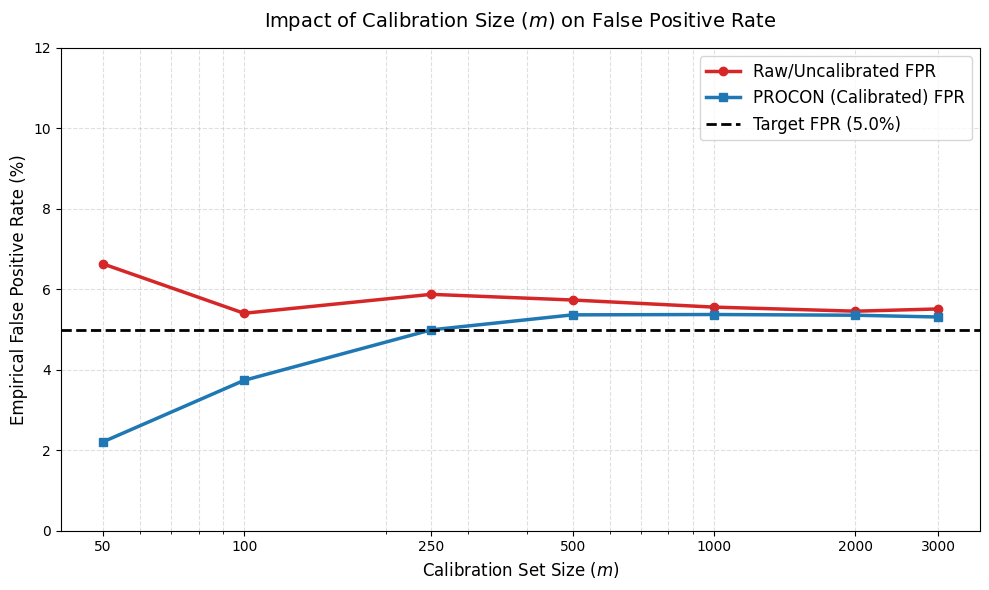

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def conformal_threshold(cal_scores, alpha):
    n = len(cal_scores)
    q_level = np.ceil((n + 1) * (1 - alpha)) / n
    return np.quantile(cal_scores, min(q_level, 1.0), method='higher')

def empirical_threshold(cal_scores, alpha):
    return np.percentile(cal_scores, (1.0 - alpha) * 100)

# 1. Load Data (Using Seed 42 for the plot)
scores = np.load('scores42.npz')
val_in_mask = scores['val_in_scope_mask']
mcp_val = scores['mcp_validation'][val_in_mask]
mcp_test = scores['mcp_test']
y_test_oos = scores['y_test_oos']

alpha = 0.05
m_values = [50, 100, 250, 500, 1000, 2000, 3000]
test_in_mask = (y_test_oos == 0)

raw_fprs = []
procon_fprs = []

# Run 50 trials per 'm' and average them for a smooth, rigorous plot
n_trials = 50

for m in m_values:
    trial_raw = []
    trial_conf = []
    for _ in range(n_trials):
        # Simulate limited calibration data by random sampling
        subset = np.random.choice(mcp_val, size=m, replace=False)

        t_raw = empirical_threshold(subset, alpha)
        t_conf = conformal_threshold(subset, alpha)

        fpr_raw = (mcp_test[test_in_mask] > t_raw).mean() * 100
        fpr_conf = (mcp_test[test_in_mask] > t_conf).mean() * 100

        trial_raw.append(fpr_raw)
        trial_conf.append(fpr_conf)

    raw_fprs.append(np.mean(trial_raw))
    procon_fprs.append(np.mean(trial_conf))

# 2. Create the Plot
plt.figure(figsize=(10, 6))

plt.plot(m_values, raw_fprs, marker='o', color='#d62728', label='Raw/Uncalibrated FPR', linewidth=2.5)
plt.plot(m_values, procon_fprs, marker='s', color='#1f77b4', label='PROCON (Calibrated) FPR', linewidth=2.5)

# Target line
plt.axhline(y=alpha*100, color='black', linestyle='--', label=f'Target FPR ({alpha*100}%)', linewidth=2)

# Formatting
plt.title('Impact of Calibration Size ($m$) on False Positive Rate', fontsize=14, pad=15)
plt.xlabel('Calibration Set Size ($m$)', fontsize=12)
plt.ylabel('Empirical False Positive Rate (%)', fontsize=12)

# Log scale spreads out the critical low-data region
plt.xscale('log')
plt.xticks(m_values, labels=[str(m) for m in m_values])
plt.ylim(0, 12)

plt.grid(True, which="both", ls="--", alpha=0.4)
plt.legend(fontsize=12, loc='upper right')
plt.tight_layout()

# Save publication-ready image
plt.savefig('fpr_vs_m_stress_test.png', dpi=300)
plt.show()

<>:96: SyntaxWarning: invalid escape sequence '\p'
<>:96: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_3570/2684367075.py:96: SyntaxWarning: invalid escape sequence '\p'
  plt.suptitle('Multi-Seed Impact of Calibration Size ($m$) on False Positive Rate (Mean $\pm$ Std across 5 Seeds)', fontsize=16, y=1.02)


Aggregating data across 5 seeds... This may take a few seconds.


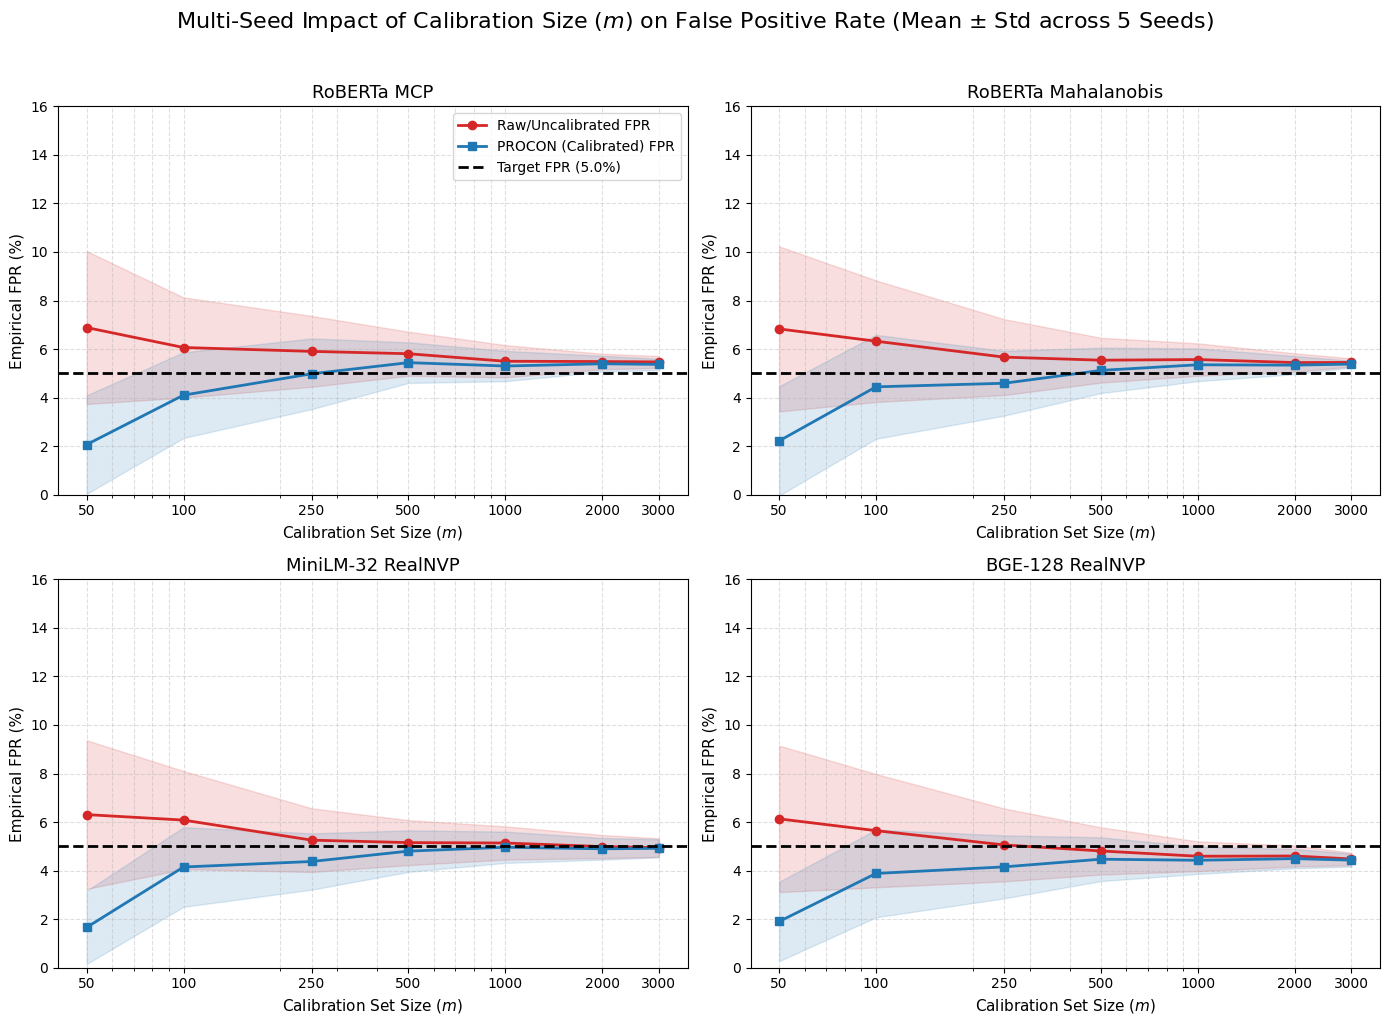

In [7]:
import numpy as np
import matplotlib.pyplot as plt

def conformal_threshold(cal_scores, alpha):
    n = len(cal_scores)
    q_level = np.ceil((n + 1) * (1 - alpha)) / n
    return np.quantile(cal_scores, min(q_level, 1.0), method='higher')

def empirical_threshold(cal_scores, alpha):
    return np.percentile(cal_scores, (1.0 - alpha) * 100)

# Setup parameters
seeds = [42, 43, 44, 45, 46]
m_values = [50, 100, 250, 500, 1000, 2000, 3000]
alpha = 0.05
n_trials = 20 # 20 random subsampling trials per seed

# Define mappings to extract from the npz files
method_keys = [
    ('RoBERTa MCP', 'mcp_validation', 'mcp_test'),
    ('RoBERTa Mahalanobis', 'maha_validation', 'maha_test'),
    ('MiniLM-32 RealNVP', 'minilm_flow_validation', 'minilm_flow_test'),
    ('BGE-128 RealNVP', 'bge_flow_validation', 'bge_flow_test')
]

# Initialize storage dictionary
results = {m_name: {'raw': {m: [] for m in m_values}, 'procon': {m: [] for m in m_values}} for m_name, _, _ in method_keys}

print("Aggregating data across 5 seeds... This may take a few seconds.")

# 1. Evaluate across all seeds and architectures
for seed in seeds:
    scores = np.load(f'scores{seed}.npz')
    val_in_mask = scores['val_in_scope_mask']
    y_test_oos = scores['y_test_oos']
    test_in_mask = (y_test_oos == 0)

    for m_name, val_key, test_key in method_keys:
        val_scores = scores[val_key][val_in_mask]
        test_scores = scores[test_key]

        for m in m_values:
            for _ in range(n_trials):
                # Simulate limited calibration data
                subset = np.random.choice(val_scores, size=m, replace=False)

                t_raw = empirical_threshold(subset, alpha)
                t_conf = conformal_threshold(subset, alpha)

                # Calculate Empirical FPR
                fpr_raw = (test_scores[test_in_mask] > t_raw).mean() * 100
                fpr_conf = (test_scores[test_in_mask] > t_conf).mean() * 100

                results[m_name]['raw'][m].append(fpr_raw)
                results[m_name]['procon'][m].append(fpr_conf)

# 2. Plotting the 2x2 Grid
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, (m_name, _, _) in enumerate(method_keys):
    ax = axes[i]

    # Calculate Means and Standard Deviations
    raw_means = [np.mean(results[m_name]['raw'][m]) for m in m_values]
    raw_stds = [np.std(results[m_name]['raw'][m]) for m in m_values]

    procon_means = [np.mean(results[m_name]['procon'][m]) for m in m_values]
    procon_stds = [np.std(results[m_name]['procon'][m]) for m in m_values]

    # Plot Raw Line + Shade
    ax.plot(m_values, raw_means, marker='o', color='#d62728', label='Raw/Uncalibrated FPR', linewidth=2)
    ax.fill_between(m_values, np.array(raw_means)-np.array(raw_stds), np.array(raw_means)+np.array(raw_stds), color='#d62728', alpha=0.15)

    # Plot PROCON Line + Shade
    ax.plot(m_values, procon_means, marker='s', color='#1f77b4', label='PROCON (Calibrated) FPR', linewidth=2)
    ax.fill_between(m_values, np.array(procon_means)-np.array(procon_stds), np.array(procon_means)+np.array(procon_stds), color='#1f77b4', alpha=0.15)

    # Plot Target Line
    ax.axhline(y=alpha*100, color='black', linestyle='--', label=f'Target FPR ({alpha*100}%)', linewidth=2)

    # Subplot Formatting
    ax.set_title(m_name, fontsize=13)
    ax.set_xlabel('Calibration Set Size ($m$)', fontsize=11)
    ax.set_ylabel('Empirical FPR (%)', fontsize=11)
    ax.set_xscale('log')
    ax.set_xticks(m_values)
    ax.set_xticklabels(m_values)
    ax.set_ylim(0, 16)
    ax.grid(True, which="both", ls="--", alpha=0.4)

    # Only add legend to the first plot to avoid clutter
    if i == 0:
        ax.legend(fontsize=10, loc='upper right')

plt.suptitle('Multi-Seed Impact of Calibration Size ($m$) on False Positive Rate (Mean $\pm$ Std across 5 Seeds)', fontsize=16, y=1.02)
plt.tight_layout()

# Save for your paper
plt.savefig('fpr_vs_m_all_methods_multiseed.png', bbox_inches='tight', dpi=300)
plt.show()

In [9]:
import numpy as np
import pandas as pd

def run_multiseed_covariate_shift(alpha=0.05, gamma=5.0):
    seeds = [42, 43, 44, 45, 46]
    all_results = []

    for seed in seeds:
        # 1. LOAD & PREPARE EXCHANGEABLE DATA
        scores = np.load(f'scores{seed}.npz')
        in_scope_pool = scores['mcp_test'][scores['y_test_oos'] == 0]

        # Shuffle pool deterministically based on current seed
        np.random.seed(seed)
        np.random.shuffle(in_scope_pool)

        cal_scores = in_scope_pool[:2000]
        test_base = in_scope_pool[2000:]
        n_cal = len(cal_scores)

        # Base Conformal Threshold
        q = np.ceil((n_cal + 1) * (1 - alpha)) / n_cal
        tau_std = np.quantile(cal_scores, min(q, 1.0), method='higher')
        fpr_base = (test_base > tau_std).mean()

        # 2. INDUCE COVARIATE SHIFT
        weights_prob = np.exp(gamma * test_base)
        weights_prob /= np.sum(weights_prob)

        shifted_indices = np.random.choice(
            len(test_base),
            size=2000,
            p=weights_prob,
            replace=True
        )
        test_shifted = test_base[shifted_indices]

        fpr_shifted = (test_shifted > tau_std).mean()

        # 3. WEIGHTED CONFORMAL PREDICTION (Oracle)
        w_cal = np.exp(gamma * cal_scores)
        w_test = np.exp(gamma * test_shifted)

        false_positives = 0
        for i in range(len(test_shifted)):
            S_test = test_shifted[i]
            w_n1 = w_test[i]

            # WCP p-value calculation
            sum_w = np.sum(w_cal) + w_n1
            weight_ge = np.sum(w_cal[cal_scores >= S_test])
            p_value = (weight_ge + w_n1) / sum_w

            if p_value <= alpha:
                false_positives += 1

        fpr_wcp = false_positives / len(test_shifted)

        all_results.append({
            'Seed': seed,
            'Base FPR': fpr_base * 100,
            'Shifted FPR (Standard)': fpr_shifted * 100,
            'Weighted FPR (WCP)': fpr_wcp * 100
        })

    # Compile DataFrame and calculate Means
    df_cov = pd.DataFrame(all_results)

    # Calculate Mean row
    mean_row = df_cov.mean().to_dict()
    mean_row['Seed'] = 'Mean'

    # Use pd.concat instead of append
    df_cov = pd.concat([df_cov, pd.DataFrame([mean_row])], ignore_index=True)

    # Format nicely
    for col in ['Base FPR', 'Shifted FPR (Standard)', 'Weighted FPR (WCP)']:
        df_cov[col] = df_cov[col].apply(lambda x: f"{x:.2f}%")

    return df_cov

# Execute and display
covariate_df = run_multiseed_covariate_shift()
print("=== COVARIATE SHIFT EXPERIMENT (5 SEEDS) ===")
display(covariate_df)

=== COVARIATE SHIFT EXPERIMENT (5 SEEDS) ===


,Seed,Base FPR,Shifted FPR (Standard),Weighted FPR (WCP)
0,42,5.12%,39.90%,4.65%
1,43,4.88%,36.15%,1.40%
2,44,4.96%,35.25%,2.25%
3,45,4.28%,36.50%,0.00%
4,46,5.68%,42.20%,5.60%
5,Mean,4.98%,38.00%,2.78%


In [11]:
print("\\begin{table*}[t]")
print(covariate_df.to_latex(index=False, column_format='lccc'))
print("\\end{table*}")

\begin{table*}[t]
\begin{tabular}{lccc}
\toprule
Seed & Base FPR & Shifted FPR (Standard) & Weighted FPR (WCP) \\
\midrule
42 & 5.12% & 39.90% & 4.65% \\
43 & 4.88% & 36.15% & 1.40% \\
44 & 4.96% & 35.25% & 2.25% \\
45 & 4.28% & 36.50% & 0.00% \\
46 & 5.68% & 42.20% & 5.60% \\
Mean & 4.98% & 38.00% & 2.78% \\
\bottomrule
\end{tabular}

\end{table*}


In [13]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from scipy.stats import multivariate_normal
import os

def run_multiseed_pca_sweep():
    seeds = [42, 43, 44, 45, 46]

    # Define models and the specific PCA dimensions we want to test for each
    models = {
        'minilm': {'name': 'MiniLM-32', 'dims': [2, 4, 8, 16, 24, 32]},
        'bge': {'name': 'BGE-128', 'dims': [8, 16, 32, 64, 96, 128]}
    }

    all_results = []

    for model_key, model_info in models.items():
        print(f"Processing {model_info['name']} across 5 seeds...")

        for d in model_info['dims']:
            auroc_list = []
            in_ll_list = []
            oos_ll_list = []

            for seed in seeds:
                artifacts_file = f'artifacts_{model_key}{seed}.npz'
                scores_file = f'scores{seed}.npz'

                try:
                    # 1. Load Data
                    artifacts = np.load(artifacts_file)
                    scores = np.load(scores_file)
                    y_test = scores['y_test_oos']

                    # 2. Extract and Center PCA Projections
                    pca_comps = artifacts['pca_components']
                    pca_mean = artifacts['pca_mean']

                    train_c = artifacts['train_embeddings'] - pca_mean
                    test_c = artifacts['test_embeddings'] - pca_mean

                    # Safely handle matrix multiplication depending on saved shape
                    if pca_comps.shape[0] == train_c.shape[1]:
                        train_pca = train_c @ pca_comps
                        test_pca = test_c @ pca_comps
                    else:
                        train_pca = train_c @ pca_comps.T
                        test_pca = test_c @ pca_comps.T

                    # 3. Subset to 'd' dimensions
                    Z_tr = train_pca[:, :d]
                    Z_te = test_pca[:, :d]

                    # 4. Fit Global Gaussian (Maximum Likelihood Estimate)
                    mu = np.mean(Z_tr, axis=0)
                    cov = np.cov(Z_tr, rowvar=False) + np.eye(d) * 1e-6

                    # 5. Calculate Log-Likelihoods on Test Set
                    ll_test = multivariate_normal.logpdf(Z_te, mean=mu, cov=cov)

                    # Append metrics for this seed
                    in_ll_list.append(ll_test[y_test == 0].mean())
                    oos_ll_list.append(ll_test[y_test == 1].mean())
                    auroc_list.append(roc_auc_score(y_test, -ll_test))

                except FileNotFoundError as e:
                    print(f"  [Warning] Missing file: {e.filename}")
                    continue

            # Aggregate across all available seeds for this dimension 'd'
            if auroc_list:
                all_results.append({
                    'Model': model_info['name'],
                    'PCA Dims': d,
                    'In-Scope LL (Mean ± Std)': f"{np.mean(in_ll_list):.2f} ± {np.std(in_ll_list):.2f}",
                    'OOS LL (Mean ± Std)': f"{np.mean(oos_ll_list):.2f} ± {np.std(oos_ll_list):.2f}",
                    'AUROC (Mean ± Std)': f"{np.mean(auroc_list):.4f} ± {np.std(auroc_list):.4f}"
                })

    # Compile and display DataFrame
    df_sweep = pd.DataFrame(all_results)
    return df_sweep

if __name__ == '__main__':
    final_df = run_multiseed_pca_sweep()
    print("\n=== Multi-Seed PCA Likelihood Sweep ===")
    display(final_df) # Use print(final_df.to_string(index=False)) if outside Jupyter

Processing MiniLM-32 across 5 seeds...
Processing BGE-128 across 5 seeds...

=== Multi-Seed PCA Likelihood Sweep ===


,Model,PCA Dims,In-Scope LL (Mean ± Std),OOS LL (Mean ± Std),AUROC (Mean ± Std)
0,MiniLM-32,2,0.48 ± 0.00,1.07 ± 0.00,0.2546 ± 0.0000
1,MiniLM-32,4,1.39 ± 0.00,2.34 ± 0.00,0.2484 ± 0.0000
2,MiniLM-32,8,3.73 ± 0.00,5.56 ± 0.00,0.1928 ± 0.0000
3,MiniLM-32,16,9.91 ± 0.00,13.12 ± 0.00,0.1612 ± 0.0000
4,MiniLM-32,24,17.48 ± 0.00,21.51 ± 0.00,0.1839 ± 0.0000
5,MiniLM-32,32,25.88 ± 0.00,30.49 ± 0.00,0.2066 ± 0.0000
6,BGE-128,8,5.26 ± 0.00,6.80 ± 0.00,0.2056 ± 0.0000
7,BGE-128,16,13.59 ± 0.00,16.22 ± 0.00,0.1879 ± 0.0000
8,BGE-128,32,34.51 ± 0.00,38.13 ± 0.00,0.2279 ± 0.0000
9,BGE-128,64,86.85 ± 0.00,89.01 ± 0.00,0.4140 ± 0.0002


In [14]:
print("\\begin{table*}[t]")
print("\\centering")
print("\\caption{PCA Dimension Sweep: Multi-Seed Likelihood and OOS Detection Performance}")
print("\\label{tab:pca_sweep_results}")
print("\\resizebox{\\textwidth}{!}{ ")
# Convert DataFrame to LaTeX string
# We use index=False to keep it clean
latex_str = final_df.to_latex(index=False,
                              column_format='lcccc',
                              escape=False,
                              caption=None)
print(latex_str)
print("}")
print("\\end{table*}")

\begin{table*}[t]
\centering
\caption{PCA Dimension Sweep: Multi-Seed Likelihood and OOS Detection Performance}
\label{tab:pca_sweep_results}
\resizebox{\textwidth}{!}{ 
\begin{tabular}{lcccc}
\toprule
Model & PCA Dims & In-Scope LL (Mean ± Std) & OOS LL (Mean ± Std) & AUROC (Mean ± Std) \\
\midrule
MiniLM-32 & 2 & 0.48 ± 0.00 & 1.07 ± 0.00 & 0.2546 ± 0.0000 \\
MiniLM-32 & 4 & 1.39 ± 0.00 & 2.34 ± 0.00 & 0.2484 ± 0.0000 \\
MiniLM-32 & 8 & 3.73 ± 0.00 & 5.56 ± 0.00 & 0.1928 ± 0.0000 \\
MiniLM-32 & 16 & 9.91 ± 0.00 & 13.12 ± 0.00 & 0.1612 ± 0.0000 \\
MiniLM-32 & 24 & 17.48 ± 0.00 & 21.51 ± 0.00 & 0.1839 ± 0.0000 \\
MiniLM-32 & 32 & 25.88 ± 0.00 & 30.49 ± 0.00 & 0.2066 ± 0.0000 \\
BGE-128 & 8 & 5.26 ± 0.00 & 6.80 ± 0.00 & 0.2056 ± 0.0000 \\
BGE-128 & 16 & 13.59 ± 0.00 & 16.22 ± 0.00 & 0.1879 ± 0.0000 \\
BGE-128 & 32 & 34.51 ± 0.00 & 38.13 ± 0.00 & 0.2279 ± 0.0000 \\
BGE-128 & 64 & 86.85 ± 0.00 & 89.01 ± 0.00 & 0.4140 ± 0.0002 \\
BGE-128 & 96 & 147.70 ± 0.01 & 144.66 ± 0.01 & 0.6048 ± 0.00